In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('/content/winequality-red.csv', sep=';')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [17]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [18]:
df = df.fillna(df.mean())
print("Missing values handled successfully!")

Missing values handled successfully!


In [19]:
alcohol = df['alcohol'].values
citric_acid = df['citric acid'].values
print("Alcohol Vector:")
print(alcohol[:10])
print("\nCitric Acid Vector:")
print(citric_acid[:10])

Alcohol Vector:
[ 9.4  9.8  9.8  9.8  9.4  9.4  9.4 10.   9.5 10.5]

Citric Acid Vector:
[0.   0.   0.04 0.56 0.   0.   0.06 0.   0.02 0.36]


In [20]:
cov_matrix = np.cov(df['alcohol'], df['density'])
print("Covariance Matrix:")
print(cov_matrix)

Covariance Matrix:
[[ 1.13564740e+00 -9.97951790e-04]
 [-9.97951790e-04  3.56202945e-06]]


In [21]:
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
print("Eigenvalues:")
print(eigenvalues)
print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[1.13564827e+00 2.68507580e-06]

Eigenvectors:
[[ 9.99999614e-01  8.78753184e-04]
 [-8.78753184e-04  9.99999614e-01]]


In [22]:
quality_counts = df['quality'].value_counts().sort_index()
print("Wine Quality Distribution:")
print(quality_counts)

Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [23]:
probabilities = df['quality'].value_counts(normalize=True).sort_index()
print("Wine Quality Probabilities:")
print(probabilities)

Wine Quality Probabilities:
quality
3    0.006254
4    0.033146
5    0.425891
6    0.398999
7    0.124453
8    0.011257
Name: proportion, dtype: float64


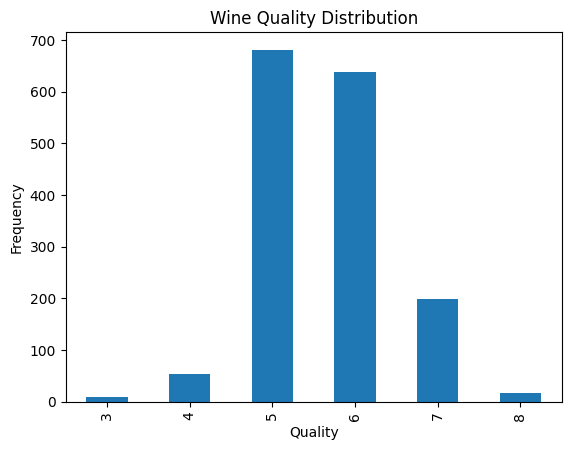

In [24]:
quality_counts.plot(kind='bar')
plt.title('Wine Quality Distribution')
plt.xlabel('Quality')
plt.ylabel('Frequency')
plt.show()

In [25]:
df.to_csv('/content/winequality_cleaned.csv', index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [26]:
print("Conclusion:")
print("1. The dataset contains 1599 red wine samples.")
print("2. Most wines have quality scores of 5 and 6.")
print("3. Quality 5 is the most common score.")
print("4. The dataset contains no missing values.")
print("5. Covariance and eigenvalues were calculated successfully.")

Conclusion:
1. The dataset contains 1599 red wine samples.
2. Most wines have quality scores of 5 and 6.
3. Quality 5 is the most common score.
4. The dataset contains no missing values.
5. Covariance and eigenvalues were calculated successfully.
